# ABC Company – Employee Data Analysis
**Module 1 – End Project**

This notebook cleans the ABC Company employee dataset (458 rows × 9 columns), answers five analysis questions and visualises each one. A data story with the key insights is at the end.

**Contents**
1. Setup & loading the data
2. Preprocessing
3. Task 1 – Employees per team
4. Task 2 – Employees by position
5. Task 3 – Predominant age group
6. Task 4 – Salary expenditure by team and position
7. Task 5 – Age vs. salary correlation
8. Data story

## 1. Setup & loading the data

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.dpi"] = 110
os.makedirs("images", exist_ok=True)

DATA_PATH = "ABC Company.xlsx"      # dataset file kept in the same folder as this notebook
df = pd.read_excel(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (458, 9)


,Name,Team,Number,Position,Age,Height,Weight,College,Salary
0,Avery Bradley,Boston Celtics,0,PG,25,2023-02-06 00:00:00,180,Texas,7730337.0
1,Jae Crowder,Boston Celtics,99,SF,25,2023-06-06 00:00:00,235,Marquette,6796117.0
2,John Holland,Boston Celtics,30,SG,27,2023-05-06 00:00:00,205,Boston University,NaN
3,R.J. Hunter,Boston Celtics,28,SG,22,2023-05-06 00:00:00,185,Georgia State,1148640.0
4,Jonas Jerebko,Boston Celtics,8,PF,29,2023-10-06 00:00:00,231,NaN,5000000.0


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 458 entries, 0 to 457
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Name      458 non-null    object 
 1   Team      458 non-null    object 
 2   Number    458 non-null    int64  
 3   Position  458 non-null    object 
 4   Age       458 non-null    int64  
 5   Height    458 non-null    object 
 6   Weight    458 non-null    int64  
 7   College   374 non-null    object 
 8   Salary    447 non-null    float64
dtypes: float64(1), int64(3), object(5)
memory usage: 32.3+ KB


In [3]:
# Missing values per column
df.isnull().sum()

,0
Name,0
Team,0
Number,0
Position,0
Age,0
Height,0
Weight,0
College,84
Salary,11


## 2. Preprocessing

**Height column.** In the raw file the heights were stored as text such as `6-2`, and Excel converted many of them into dates (e.g. `06-Feb`), so the column is corrupted. As instructed, the column is replaced with random integers between **150 and 180** (a fixed seed is used so the result is reproducible).

**Other checks.** Column names are stripped of whitespace, text columns are tidied, duplicates are checked, and missing `Salary` values are handled (see below).

In [4]:
df.columns = df.columns.str.strip()
for col in ["Name", "Team", "Position", "College"]:
    df[col] = df[col].astype("string").str.strip()

# --- Height: replace the corrupted values with random numbers in [150, 180] ---
rng = np.random.default_rng(42)
df["Height"] = rng.integers(150, 181, size=len(df))       # upper bound is exclusive -> 181
print("Height min/max:", df["Height"].min(), df["Height"].max())

# --- Duplicates ---
print("Duplicate rows:", df.duplicated().sum())

Height min/max: 150 180
Duplicate rows: 0


In [5]:
# --- Salary: make sure it is numeric, then look at the missing values ---
df["Salary"] = pd.to_numeric(df["Salary"], errors="coerce")
print("Missing salaries:", df["Salary"].isnull().sum())

# Missing salaries are filled with the median salary so that no employee is dropped
# from the headcount analyses. (Median is used because salary is heavily right-skewed.)
median_salary = df["Salary"].median()
df["Salary"] = df["Salary"].fillna(median_salary)
print("Median salary used for filling:", median_salary)

# Age is needed for tasks 3 and 5
print("Missing ages:", df["Age"].isnull().sum())
df = df.dropna(subset=["Age"])
df["Age"] = df["Age"].astype(int)
df.describe(include="all").T

Missing salaries: 11
Median salary used for filling: 2836186.0
Missing ages: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Name,458,458,Avery Bradley,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Team,458,30,New Orleans Pelicans,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Number,458.0,NaN,NaN,NaN,17.713974,15.966837,0.0,5.0,13.0,25.0,99.0
Position,458,5,SG,102,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,458.0,NaN,NaN,NaN,26.934498,4.400128,19.0,24.0,26.0,30.0,40.0
Height,458.0,NaN,NaN,NaN,164.884279,8.868461,150.0,158.0,165.0,173.0,180.0
Weight,458.0,NaN,NaN,NaN,221.543668,26.3432,161.0,200.0,220.0,240.0,307.0
College,374,118,Kentucky,22,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Salary,458.0,NaN,NaN,NaN,4785987.844978,5172406.245485,30888.0,1100150.5,2836186.0,6323553.0,25000000.0


## 3. Task 1 – Distribution of employees across teams

In [6]:
team_counts = df["Team"].value_counts()
team_summary = pd.DataFrame({
    "Employees": team_counts,
    "Percentage (%)": (team_counts / len(df) * 100).round(2)
})
team_summary

,Employees,Percentage (%)
Team,,
New Orleans Pelicans,19,4.15
Memphis Grizzlies,18,3.93
Utah Jazz,16,3.49
Milwaukee Bucks,16,3.49
New York Knicks,16,3.49
Boston Celtics,15,3.28
Los Angeles Clippers,15,3.28
Los Angeles Lakers,15,3.28
Phoenix Suns,15,3.28


/tmp/ipykernel_569/645402133.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=team_counts.values, y=team_counts.index, ax=axes[0], palette="viridis")


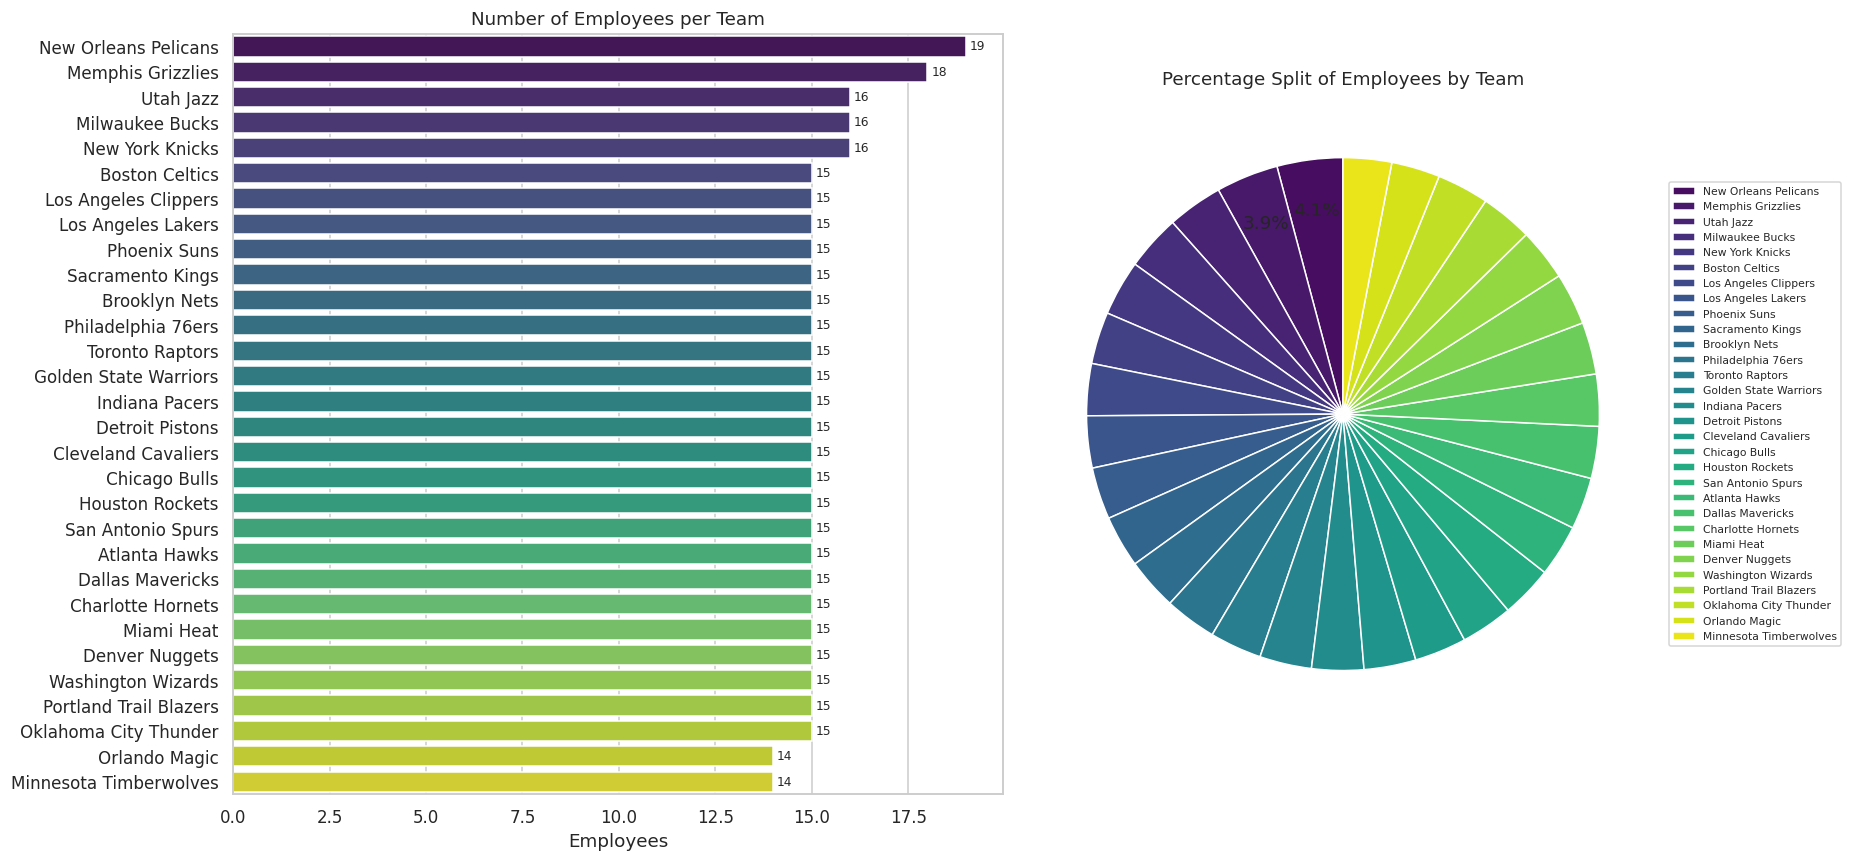

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(17, 8), gridspec_kw={"width_ratios": [1.2, 1]})

sns.barplot(x=team_counts.values, y=team_counts.index, ax=axes[0], palette="viridis")
axes[0].set_title("Number of Employees per Team")
axes[0].set_xlabel("Employees"); axes[0].set_ylabel("")
for i, v in enumerate(team_counts.values):
    axes[0].text(v + 0.1, i, str(v), va="center", fontsize=8)

# Pie of the 'percentage split' – small slices grouped for readability
pct = team_counts / len(df) * 100
axes[1].pie(pct, labels=None, autopct=lambda p: f"{p:.1f}%" if p > 3.5 else "",
            startangle=90, colors=sns.color_palette("viridis", len(pct)), pctdistance=0.8)
axes[1].set_title("Percentage Split of Employees by Team")
axes[1].legend(pct.index, loc="center left", bbox_to_anchor=(1, 0.5), fontsize=7)

plt.tight_layout()
plt.savefig("images/1_team_distribution.png", bbox_inches="tight")
plt.show()

## 4. Task 2 – Employees segregated by position

In [8]:
pos_counts = df["Position"].value_counts()
pos_summary = pd.DataFrame({
    "Employees": pos_counts,
    "Percentage (%)": (pos_counts / len(df) * 100).round(2)
})
pos_summary

,Employees,Percentage (%)
Position,,
SG,102,22.27
PF,100,21.83
PG,92,20.09
SF,85,18.56
C,79,17.25


In [9]:
# Roster of employees for each position (names grouped by position)
for pos, grp in df.groupby("Position"):
    print(f"{pos}  ({len(grp)} employees): {', '.join(grp['Name'].head(5))} ...")

C  (79 employees): Kelly Olynyk, Jared Sullinger, Tyler Zeller, Brook Lopez, Henry Sims ...
PF  (100 employees): Jonas Jerebko, Amir Johnson, Jordan Mickey, Chris McCullough, Willie Reed ...
PG  (92 employees): Avery Bradley, Terry Rozier, Marcus Smart, Isaiah Thomas, Jarrett Jack ...
SF  (85 employees): Jae Crowder, Thanasis Antetokounmpo, Carmelo Anthony, Cleanthony Early, Lance Thomas ...
SG  (102 employees): John Holland, R.J. Hunter, Evan Turner, James Young, Bojan Bogdanovic ...


/tmp/ipykernel_569/776341154.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=pos_counts.index, y=pos_counts.values, ax=axes[0], palette="mako")


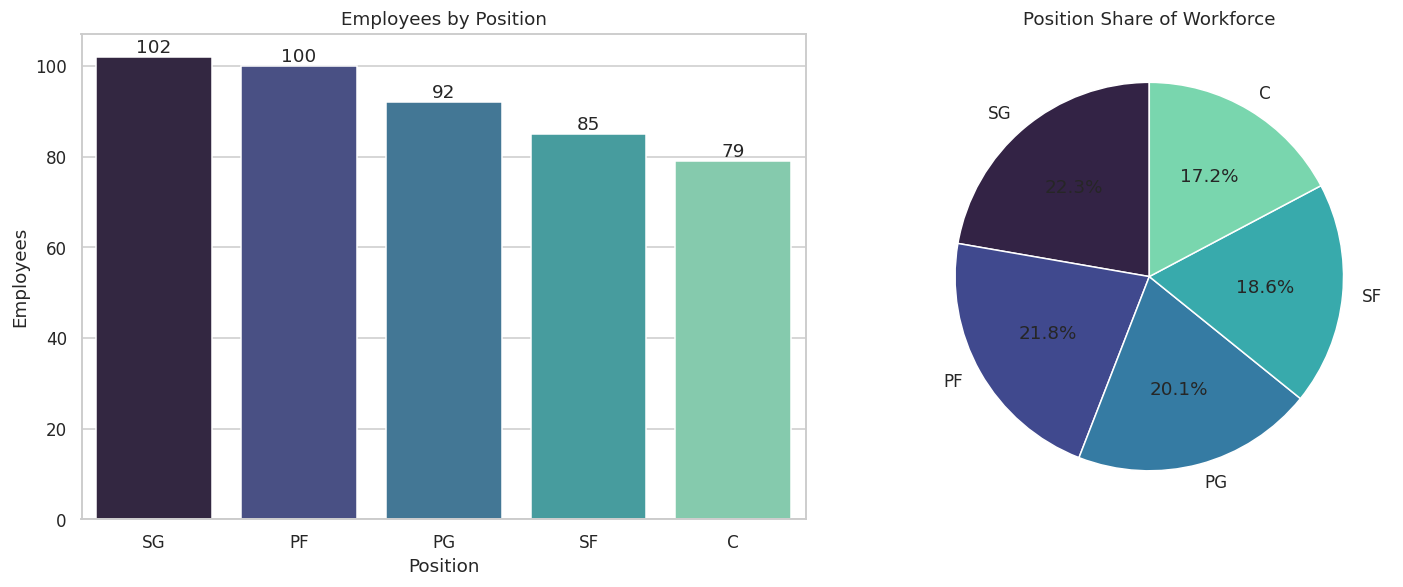

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.barplot(x=pos_counts.index, y=pos_counts.values, ax=axes[0], palette="mako")
axes[0].set_title("Employees by Position")
axes[0].set_xlabel("Position"); axes[0].set_ylabel("Employees")
for i, v in enumerate(pos_counts.values):
    axes[0].text(i, v + 1, str(v), ha="center")

axes[1].pie(pos_counts, labels=pos_counts.index, autopct="%1.1f%%", startangle=90,
            colors=sns.color_palette("mako", len(pos_counts)))
axes[1].set_title("Position Share of Workforce")
plt.tight_layout()
plt.savefig("images/2_position_distribution.png", bbox_inches="tight")
plt.show()

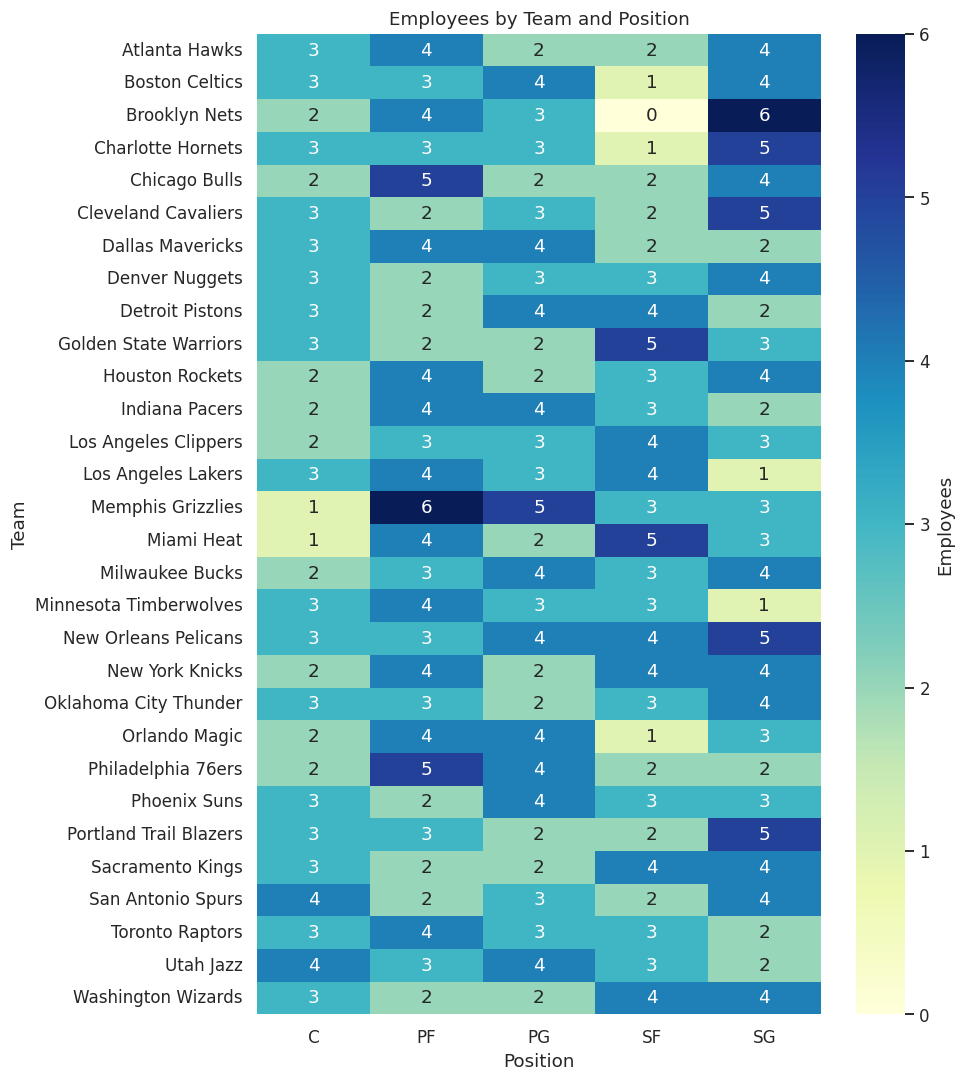

In [11]:
# Position mix inside each team (segregation by team AND position)
team_pos = pd.crosstab(df["Team"], df["Position"])
plt.figure(figsize=(9, 10))
sns.heatmap(team_pos, annot=True, fmt="d", cmap="YlGnBu", cbar_kws={"label": "Employees"})
plt.title("Employees by Team and Position")
plt.tight_layout()
plt.savefig("images/2b_team_position_heatmap.png", bbox_inches="tight")
plt.show()

## 5. Task 3 – Predominant age group

In [12]:
print("Age range:", df["Age"].min(), "-", df["Age"].max())

bins   = [0, 24, 29, 34, 39, 100]
labels = ["Under 25", "25-29", "30-34", "35-39", "40+"]
df["Age Group"] = pd.cut(df["Age"], bins=bins, labels=labels)

age_counts = df["Age Group"].value_counts().reindex(labels)
age_summary = pd.DataFrame({
    "Employees": age_counts,
    "Percentage (%)": (age_counts / len(df) * 100).round(2)
})
top_age_group = age_counts.idxmax()
print("Predominant age group:", top_age_group)
age_summary

Age range: 19 - 40
Predominant age group: 25-29


,Employees,Percentage (%)
Age Group,,
Under 25,154,33.62
25-29,182,39.74
30-34,90,19.65
35-39,29,6.33
40+,3,0.66


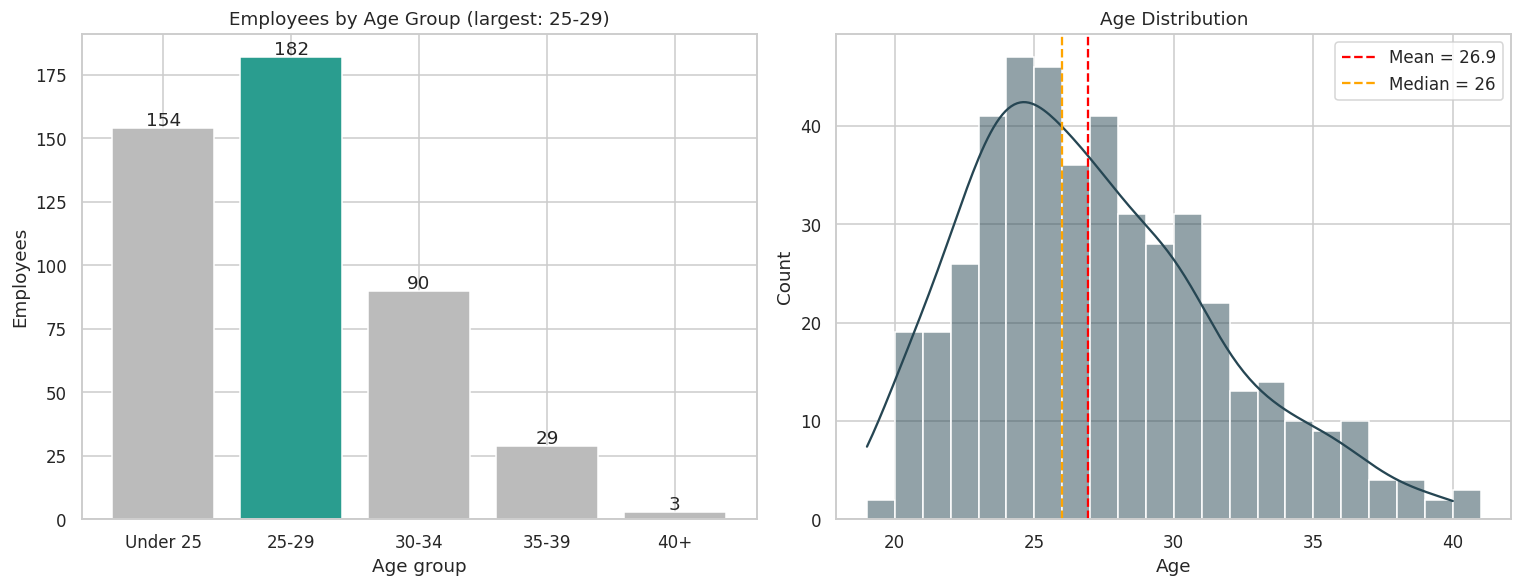

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

colors = ["#bbbbbb"] * len(labels)
colors[labels.index(top_age_group)] = "#2a9d8f"          # highlight the winner
axes[0].bar(age_counts.index.astype(str), age_counts.values, color=colors)
axes[0].set_title(f"Employees by Age Group (largest: {top_age_group})")
axes[0].set_xlabel("Age group"); axes[0].set_ylabel("Employees")
for i, v in enumerate(age_counts.values):
    axes[0].text(i, v + 1, str(v), ha="center")

sns.histplot(df["Age"], bins=range(df["Age"].min(), df["Age"].max() + 2), kde=True,
             ax=axes[1], color="#264653")
axes[1].axvline(df["Age"].mean(), color="red", ls="--", label=f"Mean = {df['Age'].mean():.1f}")
axes[1].axvline(df["Age"].median(), color="orange", ls="--", label=f"Median = {df['Age'].median():.0f}")
axes[1].set_title("Age Distribution"); axes[1].legend()
plt.tight_layout()
plt.savefig("images/3_age_distribution.png", bbox_inches="tight")
plt.show()

## 6. Task 4 – Salary expenditure by team and position

In [14]:
team_salary = df.groupby("Team")["Salary"].sum().sort_values(ascending=False)
pos_salary  = df.groupby("Position")["Salary"].sum().sort_values(ascending=False)

print(f"Team with highest salary expenditure    : {team_salary.index[0]}  (${team_salary.iloc[0]:,.0f})")
print(f"Position with highest salary expenditure: {pos_salary.index[0]}  (${pos_salary.iloc[0]:,.0f})")

print("\nTop 5 teams:")
print(team_salary.head(5).map("${:,.0f}".format))
print("\nSalary by position:")
print(pos_salary.map("${:,.0f}".format))

Team with highest salary expenditure    : Cleveland Cavaliers  ($109,824,875)
Position with highest salary expenditure: C  ($466,377,332)

Top 5 teams:
Team
Cleveland Cavaliers      $109,824,875
Los Angeles Clippers      $94,854,640
Oklahoma City Thunder     $93,765,298
Golden State Warriors     $88,868,997
Miami Heat                $88,188,045
Name: Salary, dtype: object

Salary by position:
Position
C     $466,377,332
PG    $458,193,715
PF    $451,069,408
SF    $410,857,162
SG    $405,484,816
Name: Salary, dtype: object


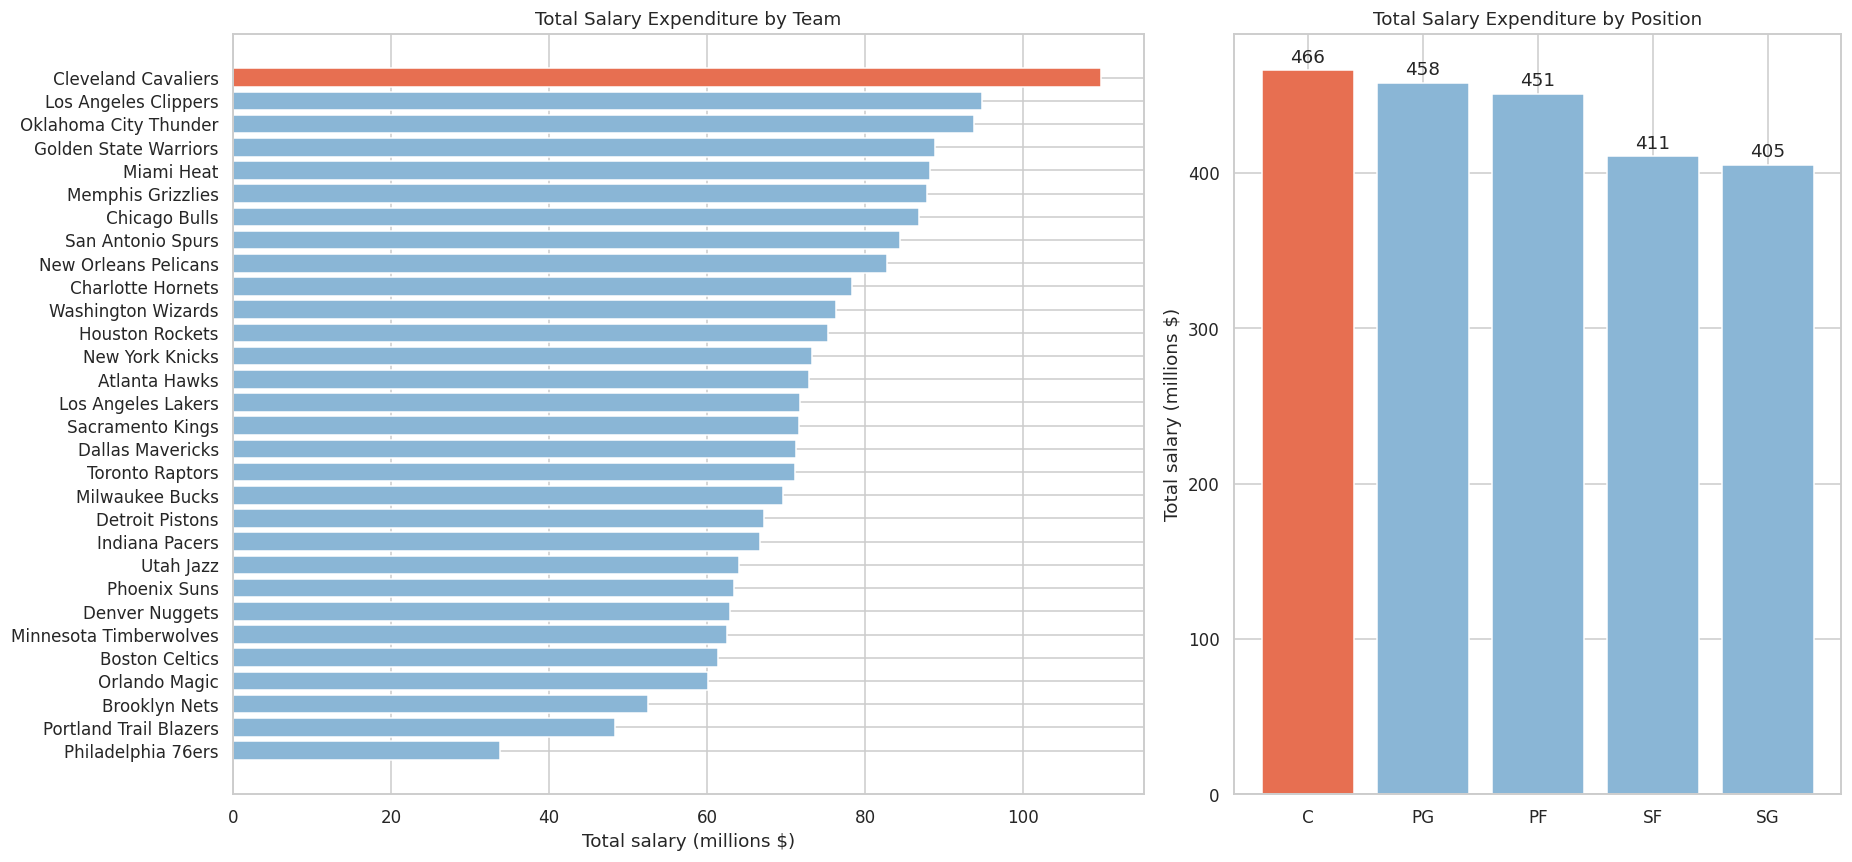

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(17, 8), gridspec_kw={"width_ratios": [1.5, 1]})

c1 = ["#e76f51" if i == 0 else "#8ab6d6" for i in range(len(team_salary))]
axes[0].barh(team_salary.index[::-1], team_salary.values[::-1] / 1e6, color=c1[::-1])
axes[0].set_title("Total Salary Expenditure by Team")
axes[0].set_xlabel("Total salary (millions $)")

c2 = ["#e76f51" if i == 0 else "#8ab6d6" for i in range(len(pos_salary))]
axes[1].bar(pos_salary.index, pos_salary.values / 1e6, color=c2)
axes[1].set_title("Total Salary Expenditure by Position")
axes[1].set_ylabel("Total salary (millions $)")
for i, v in enumerate(pos_salary.values / 1e6):
    axes[1].text(i, v + 5, f"{v:,.0f}", ha="center")

plt.tight_layout()
plt.savefig("images/4_salary_expenditure.png", bbox_inches="tight")
plt.show()

Most expensive team/position combination: ('Los Angeles Lakers', 'SF') -> $31,866,445


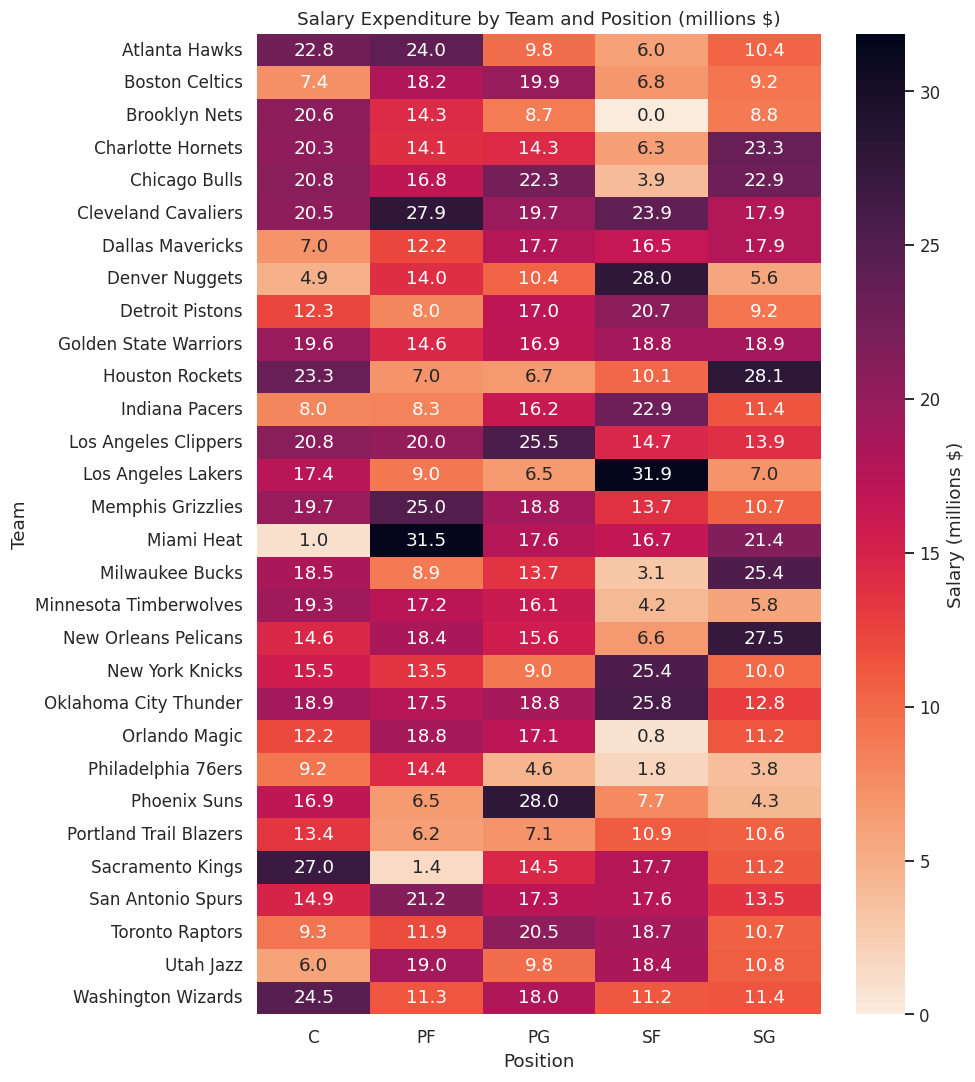

In [16]:
# Which Team + Position combination is the most expensive?
combo = df.groupby(["Team", "Position"])["Salary"].sum().sort_values(ascending=False)
print("Most expensive team/position combination:", combo.index[0], f"-> ${combo.iloc[0]:,.0f}")

pivot = df.pivot_table(index="Team", columns="Position", values="Salary", aggfunc="sum", fill_value=0) / 1e6
plt.figure(figsize=(9, 10))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="rocket_r", cbar_kws={"label": "Salary (millions $)"})
plt.title("Salary Expenditure by Team and Position (millions $)")
plt.tight_layout()
plt.savefig("images/4b_salary_heatmap.png", bbox_inches="tight")
plt.show()

## 7. Task 5 – Correlation between age and salary

In [17]:
pearson_r, pearson_p   = stats.pearsonr(df["Age"], df["Salary"])
spearman_r, spearman_p = stats.spearmanr(df["Age"], df["Salary"])
print(f"Pearson  r = {pearson_r:.3f}  (p = {pearson_p:.4f})")
print(f"Spearman ρ = {spearman_r:.3f}  (p = {spearman_p:.4f})")

Pearson  r = 0.209  (p = 0.0000)
Spearman ρ = 0.267  (p = 0.0000)


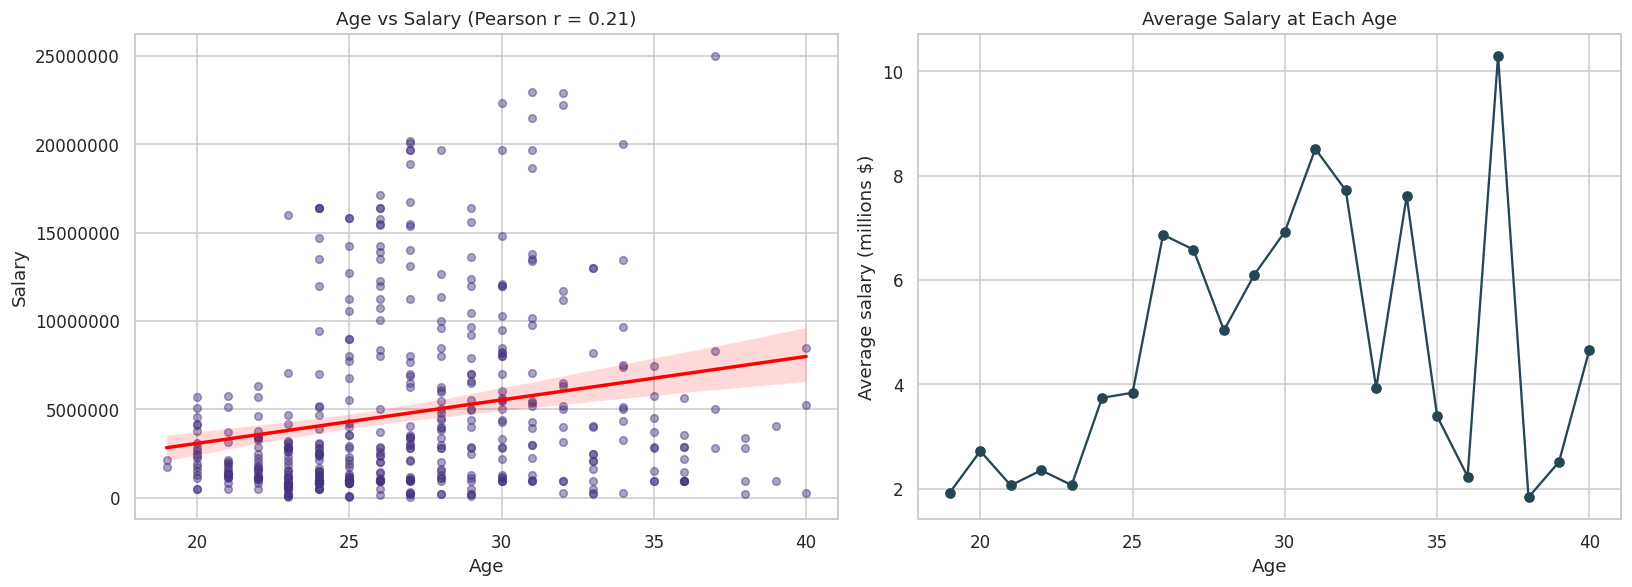

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sns.regplot(data=df, x="Age", y="Salary", ax=axes[0],
            scatter_kws={"alpha": 0.45, "s": 25}, line_kws={"color": "red"})
axes[0].set_title(f"Age vs Salary (Pearson r = {pearson_r:.2f})")
axes[0].ticklabel_format(style="plain", axis="y")

avg = df.groupby("Age")["Salary"].mean() / 1e6
axes[1].plot(avg.index, avg.values, marker="o", color="#264653")
axes[1].set_title("Average Salary at Each Age")
axes[1].set_xlabel("Age"); axes[1].set_ylabel("Average salary (millions $)")

plt.tight_layout()
plt.savefig("images/5_age_salary_correlation.png", bbox_inches="tight")
plt.show()

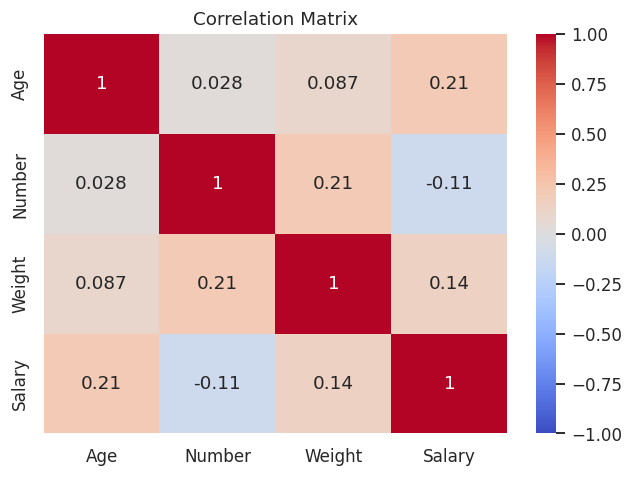

In [19]:
# Correlation matrix of numeric columns (for context)
plt.figure(figsize=(6, 4.5))
sns.heatmap(df[["Age", "Number", "Weight", "Salary"]].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.savefig("images/5b_correlation_matrix.png", bbox_inches="tight")
plt.show()

## 8. Data story – key insights

In [20]:
from IPython.display import Markdown

strength = ("very weak" if abs(pearson_r) < 0.2 else "weak" if abs(pearson_r) < 0.4
            else "moderate" if abs(pearson_r) < 0.6 else "strong")
direction = "positive" if pearson_r > 0 else "negative"
top5_share = team_salary.head(5).sum() / team_salary.sum() * 100
peak_age = avg.idxmax()
top_team_count = team_counts.index[0]

story = f'''
**Workforce.** ABC Company has **{len(df)} employees** spread across **{df["Team"].nunique()} teams**.
Team sizes are fairly balanced: they range from {team_counts.min()} to {team_counts.max()} employees
(each team is roughly {team_counts.min()/len(df)*100:.1f}–{team_counts.max()/len(df)*100:.1f}% of the workforce).
**{top_team_count}** is the largest team with {team_counts.iloc[0]} employees ({team_summary.iloc[0, 1]}%).

**Positions.** **{pos_counts.index[0]}** is the most common position ({pos_counts.iloc[0]} employees, {pos_summary.iloc[0, 1]}%),
while **{pos_counts.index[-1]}** is the least common ({pos_counts.iloc[-1]} employees, {pos_summary.iloc[-1, 1]}%).

**Age.** The workforce is young: ages run from {df["Age"].min()} to {df["Age"].max()}, with a median of {df["Age"].median():.0f}.
The predominant age group is **{top_age_group}** with {age_counts.max()} employees ({age_counts.max()/len(df)*100:.1f}%).

**Salary expenditure.** **{team_salary.index[0]}** has the highest total salary bill (${team_salary.iloc[0]/1e6:,.1f}M), while
**{team_salary.index[-1]}** has the lowest (${team_salary.iloc[-1]/1e6:,.1f}M). The top 5 teams account for {top5_share:.1f}% of all salary spend.
By position, **{pos_salary.index[0]}** is the costliest (${pos_salary.iloc[0]/1e6:,.1f}M in total).
The single most expensive team/position combination is **{combo.index[0][0]} – {combo.index[0][1]}**.

**Age vs salary.** There is a **{strength} {direction}** correlation between age and salary
(Pearson r = {pearson_r:.2f}, Spearman ρ = {spearman_r:.2f}). Average pay peaks around age **{peak_age}**.
Salary is heavily right-skewed: a small number of very highly paid employees pull the average well above the median
(mean ${df["Salary"].mean()/1e6:.2f}M vs median ${df["Salary"].median()/1e6:.2f}M).
Age alone therefore explains little of the differences in pay – experience, role and team matter more.

**Data-quality notes.** The height column was unusable (Excel had turned values like 6-2 into dates), so it was replaced by random
values between 150 and 180 as instructed and was not used for any analysis. Missing salaries were filled with the median.
'''
Markdown(story)


**Workforce.** ABC Company has **458 employees** spread across **30 teams**.
Team sizes are fairly balanced: they range from 14 to 19 employees
(each team is roughly 3.1–4.1% of the workforce).
**New Orleans Pelicans** is the largest team with 19 employees (4.15%).

**Positions.** **SG** is the most common position (102 employees, 22.27%),
while **C** is the least common (79 employees, 17.25%).

**Age.** The workforce is young: ages run from 19 to 40, with a median of 26.
The predominant age group is **25-29** with 182 employees (39.7%).

**Salary expenditure.** **Cleveland Cavaliers** has the highest total salary bill ($109.8M), while
**Philadelphia 76ers** has the lowest ($33.8M). The top 5 teams account for 21.7% of all salary spend.
By position, **C** is the costliest ($466.4M in total).
The single most expensive team/position combination is **Los Angeles Lakers – SF**.

**Age vs salary.** There is a **weak positive** correlation between age and salary
(Pearson r = 0.21, Spearman ρ = 0.27). Average pay peaks around age **37**.
Salary is heavily right-skewed: a small number of very highly paid employees pull the average well above the median
(mean $4.79M vs median $2.84M).
Age alone therefore explains little of the differences in pay – experience, role and team matter more.

**Data-quality notes.** The height column was unusable (Excel had turned values like 6-2 into dates), so it was replaced by random
values between 150 and 180 as instructed and was not used for any analysis. Missing salaries were filled with the median.
